In [5]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cbook import get_sample_data
from PIL import Image

In [6]:
image_path = get_sample_data("grace_hopper.jpg", asfileobj=False)
with Image.open(image_path) as source:
    image = np.asarray(source.convert("L"))


def show_transform(result, title, vmax=255):
    fig, axes = plt.subplots(1, 2, figsize=(8, 4), layout="constrained")
    axes[0].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[0].set_title("Original")
    axes[1].imshow(result, cmap="gray", vmin=0, vmax=vmax)
    axes[1].set_title(title)
    for ax in axes:
        ax.axis("off")
    plt.show()

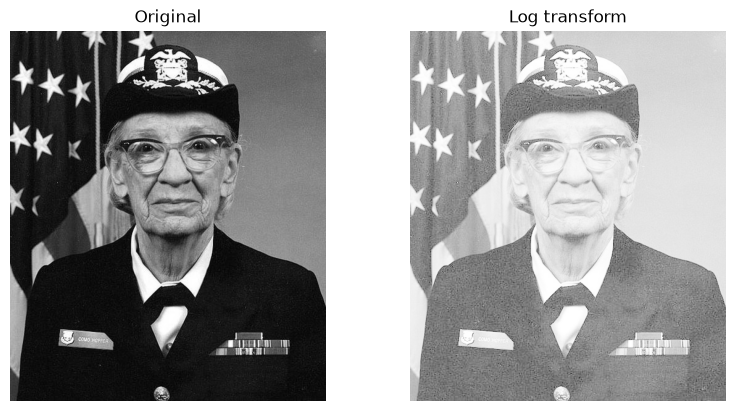

In [7]:
# Question 1
log_image = np.log1p(image.astype(float))
show_transform(log_image, "Log transform", vmax=np.log1p(255))

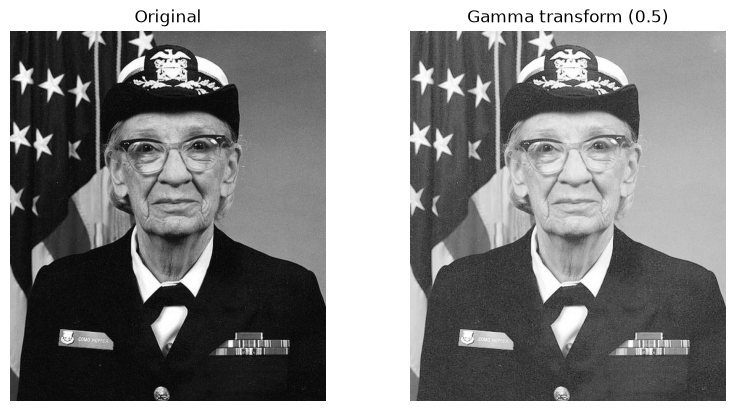

In [8]:
# Question 2
gamma = 0.5
gamma_image = np.rint(255 * (image / 255) ** gamma).astype(np.uint8)
show_transform(gamma_image, f"Gamma transform ({gamma:g})")

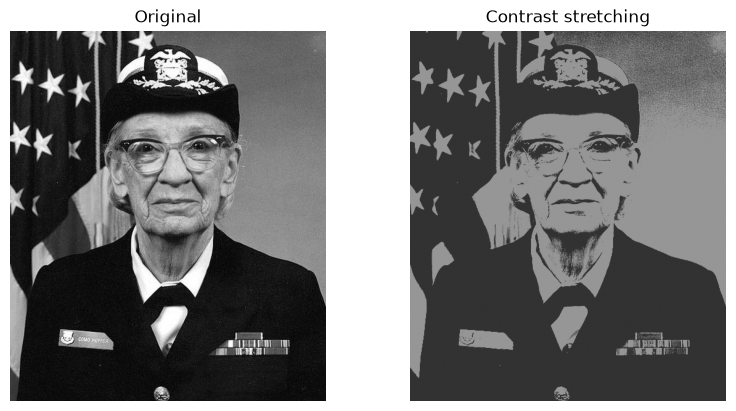

In [9]:
# Question 3
input_range = (80, 120)
output_range = (50, 150)

stretched = np.interp(image, input_range, output_range)
stretched_image = np.rint(stretched).astype(np.uint8)
show_transform(stretched_image, "Contrast stretching")